## Homework 8: Neural Networks and Deep Learning

In this homework we build a small PyTorch model that classifies curly and
straight hair. The 2026 reference setup freezes the dataset, framework
versions, architecture, split, random seed, and evaluation procedure. These
settings make the experiment reproducible while still showing why augmentation
can change a model's behavior.



## Dataset

Download the fixed archive:

```bash
wget https://github.com/SVizor42/ML_Zoomcamp/releases/download/straight-curly-data/data.zip
sha256sum data.zip
unzip -q data.zip
```



The checksum must be:

```text
9e53453e3017502f22860cb08558f0cdb343e102fb61feab75960616185e7d67  data.zip
```

The archive contains a fixed training split and a fixed held-out evaluation
split. It has 1,002 image files. One GIF is kept in the archive for provenance
but `ImageFolder` ignores it, so the training run consumes 1,001 images:

| Split | Curly | Straight | Total |
| --- | ---: | ---: | ---: |
| Train | 410 | 390 | 800 |
| Held-out evaluation | 103 | 98 | 201 |

`torchvision.datasets.ImageFolder` assigns `curly=0` and `straight=1` because
the class directories are sorted alphabetically. Do not create another random
train/test split and do not augment the held-out evaluation images.



## Environment

For the reference run, use Python 3.11 and CPU wheels:

```bash
python -m pip install -r requirements-cpu.txt
```

The important CPU wheels are `torch==2.9.0+cpu` and
`torchvision==0.24.0+cpu`. Also use
`numpy==2.3.3`, and `Pillow==11.3.0`. The CPU reference defines the grading
baseline. You can experiment on a GPU, but report the CPU run for the numeric
questions.

The directory also contains `reference_train.py`. After extracting the archive,
run `python reference_train.py --data-dir data` to produce both history files
with the complete reference procedure.



## Reproducibility rules

Run this before constructing datasets, data loaders, the model, or the
optimizer:



In [1]:
import random

import numpy as np
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.use_deterministic_algorithms(True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cpu")
torch.set_num_threads(2)


Use `num_workers=0` for both loaders. Give the training loader its own fixed
generator:



These settings remove the worker-order and GPU/cuDNN differences that made the
2025 scalar answers move between runs.



## Model and preprocessing

Use this transform for the baseline training set and, separately, for the
held-out evaluation set:



In [2]:
from torchvision import transforms

evaluation_transform = transforms.Compose([
    transforms.Resize((200, 200), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])


from pathlib import Path
from torchvision import datasets, transforms
DATA_FOLDER = Path("/workspaces/ZoomML_Homeworks/homework_8/data")
TRAIN_FOLDER = DATA_FOLDER / "train"
TEST_FOLDER = DATA_FOLDER / "test"
train_dataset =  datasets.ImageFolder(TRAIN_FOLDER, transform=evaluation_transform)
evaluation_dataset =   datasets.ImageFolder(TEST_FOLDER, transform=evaluation_transform)


from torch.utils.data import DataLoader
loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(
    train_dataset,
    batch_size=20,
    shuffle=True,
    num_workers=0,
    generator=loader_generator,
)
evaluation_loader = DataLoader(
    evaluation_dataset,
    batch_size=20,
    shuffle=False,
    num_workers=0,
)



Create the model with exactly this structure:



In [3]:

import torch.nn as nn


class HairModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Conv2d(3, 32, kernel_size=3, stride=1, padding=0)
        self.pool = nn.MaxPool2d(kernel_size=2)
        self.hidden = nn.Linear(32 * 99 * 99, 64)
        self.output = nn.Linear(64, 1)

    def forward(self, x):
        x = self.pool(nn.functional.relu(self.conv(x)))
        x = x.flatten(start_dim=1)
        x = nn.functional.relu(self.hidden(x))
        return self.output(x)




The model returns logits. Use `nn.BCEWithLogitsLoss()` and apply
`torch.sigmoid` only when calculating predictions or serving the model. Do not
put a sigmoid module in `HairModel` as well; applying it twice was an
ambiguity in the previous assignment.

Use this optimizer and loss:



In [4]:
model = HairModel().to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.002,
    momentum=0.8,
)


## Question 1 — loss and output contract

Which loss matches the model above?

- `nn.MSELoss()`
- `nn.BCEWithLogitsLoss()` [X]
- `nn.CrossEntropyLoss()`
- `nn.CosineEmbeddingLoss()`




There is one intended answer: the model emits one logit and the loss applies the
stable sigmoid-plus-binary-cross-entropy operation.





## Question 2 — parameter count

What is the total number of trainable parameters? Count biases as well and use
`sum(p.numel() for p in model.parameters())`.

- `896`
- `11214912`
- `15896912`
- `20073473`


In [5]:
sum(p.numel() for p in model.parameters())

20073473


## Training metrics

Train for 10 epochs with the baseline transform. For every epoch, evaluate the
held-out split with `model.eval()` and `torch.no_grad()`. Store these four
series in a JSON file named `history_baseline.json`:

```python
{
    "train_loss": [...],
    "train_accuracy": [...],
    "evaluation_loss": [...],
    "evaluation_accuracy": [...],
}
```

For accuracy, use `(torch.sigmoid(logits) >= 0.5)`. Use the number of examples,
not the number of batches, when averaging loss and accuracy.


In [ ]:
EPOCHS = 10
def train(model, train_loader, evaluation_loader, criterion, optimizer, device):
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "evaluation_loss": [],
        "evaluation_accuracy": [],
    }
    
    from tqdm import tqdm

    return history

In [6]:
import json
from reference_train import train_phase, make_loader

retrain = input("RETRAIN Baseline? [y/N] ").strip().lower() in {"yes", "y"}
history_path = Path("history_baseline.json")

if retrain:
    evaluation_loader = make_loader(evaluation_dataset, shuffle=False)

    baseline = train_phase(
        model,
        make_loader(train_dataset, shuffle=True, seed=SEED),
        evaluation_loader,
        criterion,
        optimizer,
        device,
    )

    with history_path.open("w") as f:
        json.dump(baseline, f, indent=2)

elif history_path.is_file():
    with history_path.open("r") as f:
        baseline = json.load(f)

else:
    raise FileNotFoundError(
        "History assente: riesegui la cella scegliendo RETRAIN=yes."
    )

baseline

100%|██████████| 10/10 [05:26<00:00, 32.67s/it]


{'train_loss': [0.6385456547141075,
  0.544144669920206,
  0.4955222845077515,
  0.43304216489195824,
  0.40478741079568864,
  0.39533531852066517,
  0.3436825366690755,
  0.2806464921683073,
  0.2236139581538737,
  0.15841433950699865],
 'train_accuracy': [0.645,
  0.7175,
  0.755,
  0.79125,
  0.80875,
  0.8075,
  0.83625,
  0.885,
  0.91,
  0.93875],
 'evaluation_loss': [0.6010399293247147,
  0.6002970076912079,
  0.6405200519371982,
  0.6274383595926845,
  0.6292919810138532,
  0.6332125963263251,
  0.6895276515638057,
  0.6497192744591936,
  0.711418602949203,
  1.0211962919441324],
 'evaluation_accuracy': [0.6567164179104478,
  0.6517412935323383,
  0.6218905472636815,
  0.6915422885572139,
  0.6616915422885572,
  0.7114427860696517,
  0.6716417910447762,
  0.7213930348258707,
  0.7164179104477612,
  0.6368159203980099]}


## Question 3 — baseline accuracy

Calculate the median of `train_accuracy` in `history_baseline.json`. Submit the
value rounded to two decimal places. The grader accepts an absolute error of
`0.05`; the answer is not selected from a fixed option list.


In [10]:

with open("/workspaces/ZoomML_Homeworks/homework_8/runs/reference/history_baseline.json", "r") as f:
    baseline_history_ref = json.load(f)

refs = {}

refs['baseline_median_train_accuracy'] = np.median(baseline_history_ref['train_accuracy'])
refs["baseline_train_loss_std_population"] = np.std(baseline_history_ref['train_loss'], ddof=0)



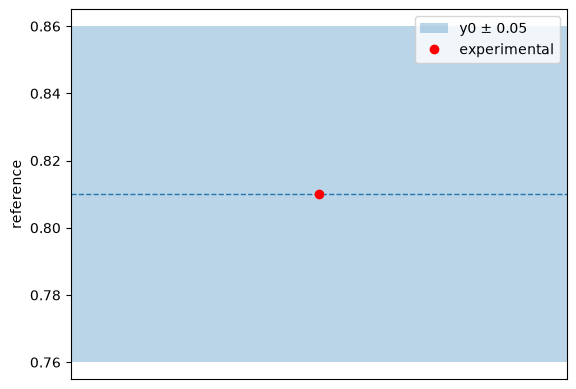

(np.True_, np.float64(0.81))

In [11]:
metrics = {key:0. for key in refs}

metrics['baseline_median_train_accuracy'] = np.median(baseline['train_accuracy'])

import matplotlib.pyplot as plt

y0 = refs['baseline_median_train_accuracy']    # valore riferimento

def plot_tolerance(y_exp, y0, tol, prec, plot=True, label="experimental", ylabel="reference"):
    y0 = round(y0, prec)
    y_exp = round(y_exp, prec)
    if plot:
        fig, ax = plt.subplots()
        ax.axhspan(y0 - tol, y0 + tol, alpha=0.3, label=f"y0 ± {tol}")
        ax.axhline(y0, linestyle="--", linewidth=1)
        ax.plot([0], [y_exp], "o", color="red", label=label)
        ax.set_xlim(-1, 1)
        ax.set_xticks([])
        ax.set_ylabel(ylabel)
        ax.legend()
        plt.show()
    return abs(y_exp - y0) <= tol, y_exp


plot_tolerance(metrics["baseline_median_train_accuracy"], 
               refs['baseline_median_train_accuracy'], 
               0.05, 
               2)


## Question 4 — baseline loss

Calculate the population standard deviation of `train_loss` in
`history_baseline.json` (for NumPy, use `np.std(values, ddof=0)`). Submit the
value rounded to three decimal places. The grader accepts an absolute error of
`0.02`.


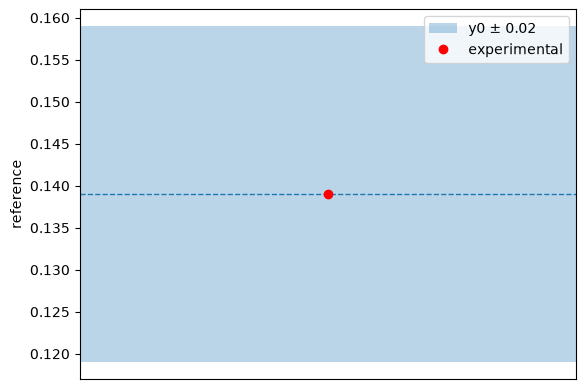

(np.True_, np.float64(0.139))

In [13]:
metrics['baseline_train_loss_std_population'] = np.std(baseline['train_loss'], ddof=0)
plot_tolerance(metrics['baseline_train_loss_std_population'], 
               refs['baseline_train_loss_std_population'], 
               0.02,
               3)





## Data augmentation

Keep the same model and optimizer. Replace only the training transform with:


In [14]:
train_transform_augmented = transforms.Compose([
    transforms.Resize((200, 200), interpolation=transforms.InterpolationMode.BILINEAR),
    transforms.RandomRotation(
        50,
        interpolation=transforms.InterpolationMode.NEAREST,
    ),
    transforms.RandomResizedCrop(
        200,
        scale=(0.9, 1.0),
        ratio=(0.9, 1.1),
        interpolation=transforms.InterpolationMode.BILINEAR,
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    ),
])





Do not recreate the model or optimizer. Train for 10 additional epochs and
write only those ten epochs to `history_augmented.json`. Continue using the
unchanged, deterministic `evaluation_dataset` and `evaluation_loader` for
every evaluation.


In [15]:
retrain = input("RETRAIN Augmented? [y/N] ").strip().lower() in {"yes", "y"}
history_path = Path("history_augmented.json")

if retrain:
    evaluation_loader = make_loader(evaluation_dataset, shuffle=False)
    augmented_dataset = datasets.ImageFolder(
        TRAIN_FOLDER,
        transform=train_transform_augmented,
    )

    augmented = train_phase(
        model,
        make_loader(augmented_dataset, shuffle=True, seed=SEED + 1),
        evaluation_loader,
        criterion,
        optimizer,
        device,
    )

    with history_path.open("w") as f:
        json.dump(augmented, f, indent=2)

elif history_path.is_file():
    with history_path.open("r") as f:
        augmented = json.load(f)

else:
    raise FileNotFoundError(
        "History assente: riesegui la cella scegliendo RETRAIN=yes."
    )

augmented

100%|██████████| 10/10 [05:59<00:00, 35.98s/it]


{'train_loss': [0.6757797911763191,
  0.6129135504364968,
  0.5899075843393803,
  0.5923107922077179,
  0.5603618547320366,
  0.5566577948629856,
  0.5432974778115749,
  0.531678818911314,
  0.5041296951472759,
  0.5386013105511666],
 'train_accuracy': [0.605,
  0.6475,
  0.68,
  0.675,
  0.71375,
  0.70875,
  0.7,
  0.72875,
  0.75625,
  0.7075],
 'evaluation_loss': [0.6552008254017996,
  0.6607642838017858,
  0.5787436581073115,
  0.5678766188929923,
  0.5680288292875337,
  0.5510144168464699,
  0.5290636126674823,
  0.5457846451161513,
  0.5556370971807792,
  0.5372932295301067],
 'evaluation_accuracy': [0.6716417910447762,
  0.6268656716417911,
  0.7114427860696517,
  0.7114427860696517,
  0.7213930348258707,
  0.7014925373134329,
  0.7412935323383084,
  0.7064676616915423,
  0.7213930348258707,
  0.7263681592039801]}


## Question 5 — augmented evaluation loss

Calculate the mean of `evaluation_loss` in `history_augmented.json`. Submit the
value rounded to three decimal places. The grader accepts an absolute error of
`0.02`.


In [16]:
with open("/workspaces/ZoomML_Homeworks/homework_8/runs/reference/history_augmented.json", "r") as f:
    augmented_history_ref = json.load(f)


refs['augmented_mean_evaluation_loss'] = np.mean(augmented_history_ref['evaluation_loss'])
metrics['augmented_mean_evaluation_loss'] = np.mean(augmented['evaluation_loss'])


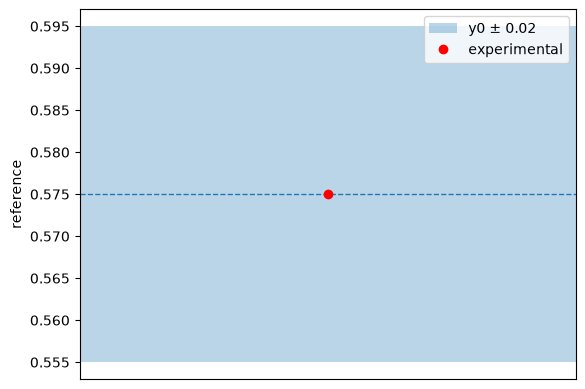

(np.True_, np.float64(0.575))

In [17]:
plot_tolerance(metrics['augmented_mean_evaluation_loss'], 
               refs['augmented_mean_evaluation_loss'], 
               0.02,
               3)



## Question 6 — augmented evaluation accuracy

Calculate the mean of the last five values in `evaluation_accuracy` in
`history_augmented.json` (epochs 6 through 10 of the augmented phase). Submit
the value rounded to two decimal places. The grader accepts an absolute error
of `0.05`.

The tolerances cover minor CPU wheel differences, while the fixed seed, loader,
split, architecture, and inference transform prevent the large uncontrolled
variation from the 2025 exercise.



In [18]:
metrics['augmented_mean_evaluation_accuracy'] = np.mean(augmented['evaluation_accuracy'][5:])
refs['augmented_mean_evaluation_accuracy'] = np.mean(augmented_history_ref['evaluation_accuracy'][5:])



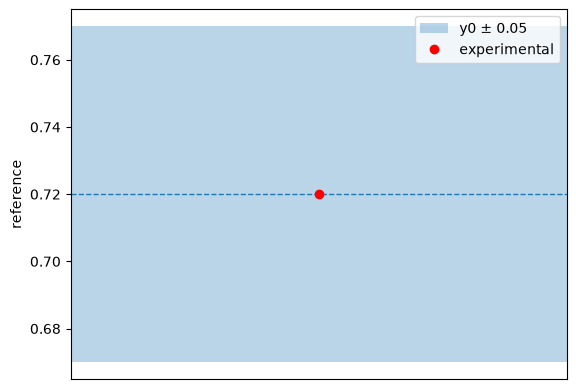

(np.True_, np.float64(0.72))

In [19]:
plot_tolerance(metrics['augmented_mean_evaluation_accuracy'], 
               refs['augmented_mean_evaluation_accuracy'], 
               0.05,
               2)




## Learning in Public

Share what you learned from this homework in a short post, screenshot, or
training-curve plot. Use `#mlzoomcamp`, tag Alexey Grigorev or DataTalksClub,
and submit the post link with your homework. Don't publish private images,
credentials, or other secrets.

See the [learning in public guide](https://datatalks.club/docs/courses/zoomcamp-logistics/learning-in-public/) for more
ideas and examples.

### Example post for LinkedIn

```text
🚀 Completed Module 8 of Machine Learning Zoomcamp 2026!

I trained an image classifier with a fixed PyTorch pipeline, recorded baseline
metrics, and measured the effect of data augmentation on a deterministic
evaluation set.

My repo: <LINK>

#mlzoomcamp @Alexey Grigorev
```

### Example post for X

```text
Trained an image classifier in Module 8 of #mlzoomcamp.

✅ Fixed the seed and evaluation transform
✅ Recorded baseline loss and accuracy
✅ Compared training with data augmentation

My repo: <LINK>
```

## Submit the results

Submit the results here:
<https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw08>.

Include the two history JSON files or a link to the notebook/script that
produced them. Numeric answers must use the precision and tolerance stated in
each question.